# TP6 — Optimiser (2/2) : hyperparamètres et compression
**ÉNONCÉ** · Durée estimée : **une journée**

## 🎯 Ce que vous allez apprendre
- Distinguer **paramètres** (appris) et **hyperparamètres** (choisis par vous)
- Faire une **recherche aléatoire** d'hyperparamètres, et la **valider** sur plusieurs graines
- **Compresser** un modèle : élagage (pruning) et quantification (TensorFlow Lite)
- Juger un **compromis précision / taille**, avec des chiffres

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`random.choice`  ·  `random.seed`  ·  `pd.DataFrame.sort_values`  ·  `keras_tuner.RandomSearch`  ·  `np.quantile`  ·  `clone_model`  ·  `set_weights`  ·  `tf.lite.TFLiteConverter`  ·  `tf.lite.Interpreter`  ·  `os.path.getsize`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)
import random, tensorflow as tf

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Préparer : un jeu de validation et une fonction d'essai
Pour choisir des hyperparamètres, on compare **sur un jeu de validation, jamais sur le test** : sinon le test n'est plus « jamais vu » et son verdict est faussé. On découpe donc l'apprentissage en deux. La fonction `essayer` entraîne un réseau avec les réglages donnés et renvoie sa **précision de validation**.

In [2]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

def essayer(neurones=32, couches=2, dropout=0.0, lr=1e-3, batch=32, seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(64,))])
    for _ in range(couches):
        m.add(layers.Dense(neurones, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=batch, callbacks=[arret], verbose=0)
    acc_val = float(np.mean(np.argmax(m.predict(X_val, verbose=0), axis=1) == y_val))
    return acc_val, m

acc_val_defaut, _ = essayer()
bruit_val = 1.96 * np.sqrt(acc_val_defaut * (1 - acc_val_defaut) / len(y_val))
print(f"Réglage par défaut : précision de validation = {acc_val_defaut:.3f}")
print(f"Avec {len(y_val)} images de validation, une différence inférieure à environ {bruit_val:.3f} est dans le bruit.")

Réglage par défaut : précision de validation = 0.952
Avec 270 images de validation, une différence inférieure à environ 0.026 est dans le bruit.


## 🎯 Étape 2 — Explorer le taux d'apprentissage
Le **taux d'apprentissage** est la taille du pas de chaque correction. C'est souvent **l'hyperparamètre le plus important**.

**À faire :** Avec `essayer`, testez les taux **0,0001 / 0,001 / 0,01 / 0,1** (autres réglages par défaut). Rangez les précisions de validation dans un dictionnaire `scores_lr` (clé = taux) et tracez-les (axe horizontal logarithmique).

> 💡 **Indice** : `plt.xscale("log")`. Une boucle `for lr in (...)`.

In [ ]:
scores_lr = {}
# TODO
for lr in (0.0001, 0.001, 0.01, 0.1):
    acu, _ = essayer(lr=lr)
    scores_lr[lr] = acu

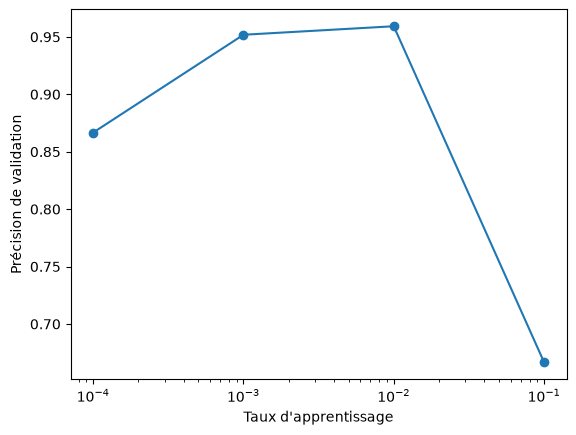

In [6]:
plt.plot(scores_lr.keys(), scores_lr.values(), 'o-')
plt.xscale("log")
plt.xlabel("Taux d'apprentissage")
plt.ylabel("Précision de validation")
plt.show()

In [7]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_lr) == 4, '4 taux testés', 'Attendu 4 résultats')

✅ 4 taux testés


In [8]:
display(scores_lr)

{0.0001: 0.8666666666666667,
 0.001: 0.9518518518518518,
 0.01: 0.9592592592592593,
 0.1: 0.6666666666666666}

### ✍️ Question
**Que se passe-t-il aux deux extrêmes (taux très petit, taux très grand) ? Les écarts dépassent-ils le bruit mesuré plus haut ?**

*Votre réponse (2 à 4 lignes) :*

> Avec un taux tres petit, le modèle n'est pas assez précis (0.87), surement du a un apprentissage trop lent. Avec un taux tres grand, le modèle est encore moins précis (0.67), surement du a des erreurs d'apprentissag, faute a un apprentissage trop rapide cette fois-ci.

> Les écarts dépassent le bruit mesuré (0.026), on pert 0.10 sur le petit, et 0.3 sur le grand.

## 🎯 Étape 3 — Recherche aléatoire
Tester toutes les combinaisons (une **grille**) explose vite : 4 × 3 × 5 × 3 × 3 = 540 réseaux. La **recherche aléatoire** en tire seulement quelques-unes au hasard, et marche souvent aussi bien à budget égal.

**À faire :** **D'abord**, tirez **15 configurations au hasard** (après `random.seed(0)`) dans une liste `configs`, parmi : `neurones` ∈ {16, 32, 64, 128}, `couches` ∈ {1, 2, 3}, `dropout` ∈ {0, 0.1, 0.2, 0.3, 0.5}, `lr` ∈ {0.001, 0.003, 0.01}, `batch` ∈ {16, 32, 64}. **Ensuite**, évaluez chacune avec `essayer`. Rangez le tout dans un tableau **`recherche`** (une colonne par réglage + `acc_val`), **trié par `acc_val` décroissant**. Vérifiez que vos 15 configurations sont bien **différentes**.

> 💡 **Indice** : `random.choice(liste)`. `pd.DataFrame(liste_de_dicts).sort_values(..., ascending=False)`. ⚠️ **Piège** : `keras.utils.set_random_seed` (appelé dans `essayer`) réinitialise **aussi** le module `random` de Python. Si vous tirez une configuration, puis entraînez, puis retirez, vous retomberez toujours sur la même. D'où l'ordre : tirer tout **avant** d'entraîner.

In [14]:
neurones = [16, 32, 64, 128]
couches = [1, 2, 3]
dropouts = [0.0, 0.1, 0.2, 0.3, 0.5]
learning_rates = [0.001, 0.003, 0.01]
batchs = [16, 32, 64]

random.seed(0)
configs = []
while len(configs) < 15:
    config = {
        'neurones': random.choice(neurones),
        'couches': random.choice(couches),
        'dropout': random.choice(dropouts),
        'lr': random.choice(learning_rates),
        'batch': random.choice(batchs) }
    if config not in configs:   # Vérifie que la config n'existe pas encore
        configs.append(config)
display(configs) 
# TODO : d'abord tirer les 15 configurations (liste configs), ensuite les évaluer


[{'neurones': 128, 'couches': 2, 'dropout': 0.0, 'lr': 0.003, 'batch': 64},
 {'neurones': 128, 'couches': 2, 'dropout': 0.2, 'lr': 0.003, 'batch': 32},
 {'neurones': 32, 'couches': 3, 'dropout': 0.1, 'lr': 0.003, 'batch': 16},
 {'neurones': 16, 'couches': 3, 'dropout': 0.2, 'lr': 0.01, 'batch': 64},
 {'neurones': 32, 'couches': 2, 'dropout': 0.0, 'lr': 0.01, 'batch': 16},
 {'neurones': 64, 'couches': 2, 'dropout': 0.5, 'lr': 0.001, 'batch': 32},
 {'neurones': 128, 'couches': 2, 'dropout': 0.5, 'lr': 0.01, 'batch': 16},
 {'neurones': 128, 'couches': 2, 'dropout': 0.5, 'lr': 0.003, 'batch': 16},
 {'neurones': 16, 'couches': 1, 'dropout': 0.3, 'lr': 0.01, 'batch': 64},
 {'neurones': 16, 'couches': 3, 'dropout': 0.3, 'lr': 0.003, 'batch': 16},
 {'neurones': 64, 'couches': 3, 'dropout': 0.0, 'lr': 0.001, 'batch': 64},
 {'neurones': 32, 'couches': 1, 'dropout': 0.1, 'lr': 0.01, 'batch': 32},
 {'neurones': 16, 'couches': 1, 'dropout': 0.2, 'lr': 0.01, 'batch': 32},
 {'neurones': 16, 'couches'

### Autre manière de faire

> 💡 **Tirage sans remise** : `random.sample` pioche 15 combinaisons **distinctes** dans la grille complète (540 possibles) — l'unicité est garantie par construction.

```python
import itertools

random.seed(0)
grille = list(itertools.product(neurones, couches, dropouts, learning_rates, batchs))  # 540 combos
tirages = random.sample(grille, 15)   # sans remise → unicité garantie

configs = [
    dict(zip(('neurones', 'couches', 'dropout', 'lr', 'batch'), t))
    for t in tirages
]

display(configs)
```

In [ ]:
# Essai des configurations
essais = []
for config in configs:
    acc, _ = essayer(**config)
    essais.append(config | {'acc_val': acc})

recherche = (pd.DataFrame(essais)
             .sort_values('acc_val', ascending=False)
             .reset_index(drop=True))
display(recherche)

,neurones,couches,dropout,lr,batch,acc_val
0,128,2,0.5,0.003,16,0.981481
1,16,1,0.3,0.010,64,0.977778
2,64,3,0.0,0.001,64,0.977778
3,128,2,0.2,0.003,32,0.974074
4,32,2,0.0,0.010,16,0.970370
5,64,2,0.5,0.001,32,0.966667
6,32,3,0.1,0.003,16,0.966667
7,32,1,0.1,0.010,32,0.966667
8,16,1,0.2,0.010,32,0.962963
9,128,2,0.5,0.010,16,0.959259


In [19]:
# ✅ Contrôle (ne pas modifier)
nb_differentes = len(recherche.drop(columns='acc_val').drop_duplicates())
controle(len(recherche) == 15 and recherche['acc_val'].is_monotonic_decreasing and nb_differentes >= 12, '15 essais triés, %d configurations différentes' % nb_differentes, 'Attendu 15 lignes triées et au moins 12 configurations différentes (avez-vous tiré avant d\'entraîner ?)')

✅ 15 essais triés, 15 configurations différentes


### ✍️ Question
**Quel écart y a-t-il entre le meilleur et le pire essai ? Le meilleur est-il réellement meilleur que le réglage par défaut, compte tenu du bruit ?**

*Votre réponse (2 à 4 lignes) :*

> Le meilleur essai donne une précision de 0.981, contre 0.959 pour le pire. Le reglage par défaut donnait une précision de 0.952. La différence entre le meilleur essai et le réglage par défaut est donc de 0.981 - 0.952 = 0.029. Ce qui est au dessus du bruit de 0.003 point, ce qui est mineur mais tout de meme significatif.

## Étape 4 — Bonus : la même recherche avec Keras Tuner
Un outil dédié automatise la recherche et garde la trace des essais. **À installer** : `pip install keras-tuner tensorboard`. Cette cellule est un bonus : si elle ne s'exécute pas, la suite du TP n'en dépend pas.

In [21]:
try:
    import keras_tuner as kt
    def construire_hp(hp):
        m = keras.Sequential([layers.Input(shape=(64,))])
        for _ in range(hp.Int("couches", 1, 3)):
            m.add(layers.Dense(hp.Choice("neurones", [16, 32, 64, 128]), activation="relu"))
            m.add(layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
        m.add(layers.Dense(10, activation="softmax"))
        m.compile(optimizer=keras.optimizers.Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        return m
    tuner = kt.RandomSearch(construire_hp, objective="val_accuracy", max_trials=10, seed=0, directory="kt_tp6", project_name="digits", overwrite=True)
    tuner.search(X_tr, y_tr, validation_data=(X_val, y_val), epochs=30, batch_size=32,
                 callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    print("Meilleurs hyperparamètres trouvés par Keras Tuner :", tuner.get_best_hyperparameters(1)[0].values)
except ImportError:
    print("keras-tuner n'est pas installé : bonus ignoré (pip install keras-tuner tensorboard)")

Meilleurs hyperparamètres trouvés par Keras Tuner : {'couches': 1, 'neurones': 128, 'dropout': 0.5, 'lr': 0.003}


## 🎯 Étape 5 — Valider sur plusieurs graines
Le meilleur essai de la recherche a pu avoir de la **chance**. Pour le savoir, on **répète** : la meilleure configuration et la configuration par défaut, **5 fois chacune** avec des graines différentes.

**À faire :** Récupérez la meilleure configuration de `recherche` (1re ligne) dans `meilleure` (dictionnaire des 5 réglages, sans `acc_val`). Avec `essayer`, calculez les précisions de validation de la configuration par défaut (`scores_defaut`) puis de la meilleure (`scores_meilleure`) pour les graines **0 à 4**. Calculez `gain` (différence des moyennes) et affichez une **conclusion automatique** : « réel » si `gain > bruit_val`, sinon « dans le bruit ».

> 💡 **Indice** : `recherche.iloc[0]`, `.to_dict()`. Attention aux types : `int(...)` pour `neurones`, `couches`, `batch`.

In [ ]:
# meilleurs hyperparamètres de keras_tuner
# meilleure = {'neurones': 128, 'couches': 1, 'batch': 32, 'lr': 0.003, 'dropout': 0.5} 

# meilleure parametres suites a la recherche aléatoire
ligne = recherche.iloc[0]
meilleure = {
    'neurones': int(ligne['neurones']),
    'couches': int(ligne['couches']),
    'dropout': float(ligne['dropout']),
    'lr':       float(ligne['lr']),
    'batch':    int(ligne['batch']),
}

# 5 graines pour chaque configuration
scores_defaut, scores_meilleure = [], []
for s in range(5):
    acc_d, _ = essayer(seed=s)                 # réglage par défaut (sans arguments)
    acc_m, _ = essayer(**meilleure, seed=s)    # meilleure configuration
    scores_defaut.append(acc_d)
    scores_meilleure.append(acc_m)

# 3) Gain + conclusion automatique
gain = float(np.mean(scores_meilleure) - np.mean(scores_defaut))
conclusion = "réel" if gain > bruit_val else "dans le bruit"
print(f"Gain = {gain:.3f} (bruit ≈ {bruit_val:.3f}) → gain {conclusion}")

Gain = 0.006 (bruit ≈ 0.026) → gain dans le bruit


- **Keras_tuner** : Gain = 0.013 (bruit ≈ 0.026) → gain dans le bruit
- **Random** : Gain = 0.006 (bruit ≈ 0.026) → gain dans le bruit

In [27]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_defaut) == 5 and len(scores_meilleure) == 5 and 'neurones' in meilleure, 'Deux séries de 5 graines', 'Attendu 5 valeurs dans chaque liste et un dictionnaire meilleure')

✅ Deux séries de 5 graines


### ✍️ Question
**L'optimisation d'hyperparamètres a-t-elle apporté un gain démontré ? Est-ce un échec si ce n'est pas le cas ?**

*Votre réponse (2 à 4 lignes) :*

> Aucun gain réel démontré, car le gain est dans le bruit. Je ne dirais pas que ce fut un echec, je dirais que l'optimisation n'a pas marchée.

## 🎯 Étape 6 — Évaluer le modèle final, une seule fois sur le test
On entraîne la meilleure configuration retenue, puis on mesure **une seule fois** sur le jeu de test, resté intact jusqu'ici.

**À faire :** Entraînez la meilleure configuration avec `essayer(**meilleure)` (graine 42) pour obtenir `modele_final`. Calculez `acc_test_final` sur `X_test`.

> 💡 **Indice** : `essayer` renvoie un couple `(précision de validation, modèle)`.

In [ ]:
# TODO : modele_final et acc_test_final
meilleure = {'neurones': 128, 'couches': 1, 'batch': 32, 'lr': 0.003, 'dropout': 0.5}

_, modele_final = essayer(**meilleure)
acc_test_final = modele_final.evaluate(X_test, y_test)[1]

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9800 - loss: 0.0596


In [32]:
# Pour tester si le resultat est le meme qu'avec evaluate()
acc_test_final = float(np.mean(np.argmax(modele_final.predict(X_test, verbose=0), axis=1) == y_test))
acc_test_final

0.98

In [33]:
# ✅ Contrôle (ne pas modifier)
controle(acc_test_final > 0.9, 'Modèle final : %.3f sur le test' % acc_test_final, 'Attendu plus de 0.9')

✅ Modèle final : 0.980 sur le test


## 🎯 Étape 7 — Compression 1 : l'élagage
L'**élagage** (pruning) met à zéro les poids les plus proches de zéro : ils contribuent peu. Un modèle avec beaucoup de zéros peut être stocké et calculé plus efficacement. Jusqu'où peut-on aller sans perdre en précision ?

**À faire :** Pour des taux **0, 50, 80, 90 et 95 %**, mettez à zéro les poids (matrices seulement, pas les biais) dont la **valeur absolue est sous le quantile** correspondant, puis mesurez la précision test du modèle élagué. Rangez dans un dictionnaire `resultats_elagage` (clé = taux, de 0 à 0.95).

> 💡 **Indice** : `modele_final.get_weights()` renvoie une liste ; les matrices ont `ndim == 2`. `np.quantile(np.abs(...), taux)`. Pour évaluer un jeu de poids : `keras.models.clone_model(modele_final)` puis `set_weights`.

In [ ]:
# TODO : resultats_elagage
resultats_elagage = {}

for taux in (0, 0.5, 0.8, 0.9, 0.95):
    # 1) Nouvelle liste de poids : matrices (ndim==2) élaguées, biais intacts
    poids = []
    for w in modele_final.get_weights():
        if w.ndim == 2:
            seuil = np.quantile(np.abs(w), taux)   # quantile des valeurs absolues
            w = np.where(np.abs(w) < seuil, 0.0, w) # strictement sous le seuil → zéro
        poids.append(w)

    # 2) Même architecture, poids élagués
    m = keras.models.clone_model(modele_final)
    m.set_weights(poids)

    # 3) Précision test du modèle élagué (pas d'evaluate ici car cela aurait nécéssité une nouvelle compilation, a chaque fois)
    acc = float(np.mean(np.argmax(m.predict(X_test, verbose=0), axis=1) == y_test))
    resultats_elagage[taux] = acc

print(resultats_elagage)

{0: 0.98, 0.5: 0.9822222222222222, 0.8: 0.9244444444444444, 0.9: 0.6333333333333333, 0.95: 0.17777777777777778}


In [35]:
# ✅ Contrôle (ne pas modifier)
controle(abs(resultats_elagage[0] - acc_test_final) < 1e-9 and resultats_elagage[0.95] <= resultats_elagage[0], 'Élagage cohérent : 0 % = modèle original', 'Attendu : 0 % identique au modèle final, et 95 % pas meilleur')

✅ Élagage cohérent : 0 % = modèle original


## 🎯 Étape 8 — Compression 2 : la quantification
La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : le fichier est environ **4 fois plus petit** et le calcul plus rapide. C'est la technique de compression la plus utilisée. TensorFlow Lite la fait en quelques lignes.

**À faire :** Convertissez `modele_final` en modèle TensorFlow Lite quantifié (`tf.lite.Optimize.DEFAULT`). Mesurez `taille_keras` (taille en octets du modèle sauvegardé au format `.keras`) et `taille_tflite`. Vérifiez la précision du modèle quantifié sur le test avec l'interpréteur TFLite : `acc_tflite`.

> 💡 **Indice** : `modele_final.save("fichier.keras")`, `os.path.getsize`. `tf.lite.TFLiteConverter.from_keras_model`, `.optimizations`, `.convert()`. `tf.lite.Interpreter(model_content=...)`, `allocate_tensors`, `set_tensor`, `invoke`, `get_tensor`.

In [39]:
# TODO : taille_keras, taille_tflite, acc_tflite
DOSSIER_MODELES = "/mnt/c/Users/Utilisateur/TP-CODE/DeepLearning_RNN_Moons/models/"

chemin_modele_final = os.path.join(DOSSIER_MODELES, "modele_final.keras")

modele_final.save(chemin_modele_final)
taille_keras = os.path.getsize(chemin_modele_final)
taille_keras

138564

In [43]:
chemin_modele_lite = os.path.join(DOSSIER_MODELES, "modele_final.tflite")

convertisseur = tf.lite.TFLiteConverter.from_keras_model(modele_final)   # prépare la conversion
convertisseur.optimizations = [tf.lite.Optimize.DEFAULT]                 # active la quantification
modele_lite = convertisseur.convert()

with open(chemin_modele_lite, "wb") as f:                 # on écrit les octets à la main
    f.write(modele_lite)

taille_tflite = os.path.getsize(chemin_modele_lite)
taille_tflite

INFO:tensorflow:Assets written to: /tmp/tmpdtuzx7nd/assets


INFO:tensorflow:Assets written to: /tmp/tmpdtuzx7nd/assets


Saved artifact at '/tmp/tmpdtuzx7nd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64), dtype=tf.float32, name='keras_tensor_234')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  126502201506512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126502166591248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126502166593168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126502166590672: TensorSpec(shape=(), dtype=tf.resource, name=None)


13600

In [ ]:
# Précision du modèle quantifié, mesurée avec l'interpréteur TFLite

# 1) L'interpréteur joue le rôle de "model.predict" pour un modèle TFLite.
#    (variante équivalente de la consigne : tf.lite.Interpreter(model_content=modele_lite))
interprete = tf.lite.Interpreter(model_path=chemin_modele_lite)
interprete.allocate_tensors()   # réserve la mémoire des tenseurs d'entrée/sortie — obligatoire avant toute prédiction

# 2) Descriptifs de l'entrée et de la sortie du réseau :
#    forme, dtype, et surtout "index" = le n° du tiroir où écrire / lire les données
entree = interprete.get_input_details()[0]
sortie = interprete.get_output_details()[0]

# 3) L'interpréteur ne fait pas de lots (batch) : on prédit image par image
predictions = []
for x in X_test:
    # On place l'image dans le tenseur d'entrée :
    #   reshape(1, 64)          → une seule image de 64 pixels (lot de taille 1)
    #   astype(np.float32)      → l'interpréteur exige du float32, X_test est en float64
    interprete.set_tensor(entree["index"], x.reshape(1, 64).astype(np.float32))
    interprete.invoke()          # exécute le réseau : entrée → sortie
    # On lit le tenseur de sortie : 10 probabilités (1 par chiffre), [0] retire la dimension du lot
    predictions.append(interprete.get_tensor(sortie["index"])[0])

# 4) Précision : classe prédite = probabilité la plus forte (argmax), comparée à l'étiquette vraie
acc_tflite = float(np.mean(np.argmax(predictions, axis=1) == y_test))

/home/romain/venvs/DeepLearning_RNN_Moons/lib/python3.13/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [45]:
print(f"Keras : {taille_keras:,} octets | TFLite : {taille_tflite:,} octets "
      f"({taille_keras / taille_tflite:.1f}× plus petit)")
print(f"Précision test : original = {acc_test_final:.3f}, quantifié = {acc_tflite:.3f}")

Keras : 138,564 octets | TFLite : 13,600 octets (10.2× plus petit)
Précision test : original = 0.980, quantifié = 0.980


In [46]:
# ✅ Contrôle (ne pas modifier)
controle(taille_tflite < taille_keras and abs(acc_tflite - acc_test_final) < 0.03, 'Modèle plus petit, précision conservée', 'Attendu : un fichier plus petit et une précision proche (écart < 0.03)')

✅ Modèle plus petit, précision conservée


### ✍️ Question
**Quel compromis choisiriez-vous entre taille, vitesse et précision pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Votre réponse (2 à 4 lignes) :*

> Je mettrais le modèle quantifié TFLite en production : il est 10 fois plus petit (13 600 octets contre 138 564) pour exactement la même précision (0.980 sur le test), et les calculs en 8 bits sont plus rapides. L'élagage n'apporte rien ici : à 50 % le gain (0.982 contre 0.980, soit 0.002) est dans le bruit (environ 0.013 pour 450 images), et au-delà la précision s'effondre (0.924 à 80 %, 0.178 à 95 %). Le quantifié est donc le meilleur choix : plus petit, plus rapide, et tout aussi précis.

## ✅ Ce qu'il faut retenir
- **Paramètres** = appris par le modèle. **Hyperparamètres** = choisis par vous (taux d'apprentissage, neurones, couches, dropout, batch…).
- On les compare **sur la validation, jamais sur le test**, et on **répète sur plusieurs graines**.
- Un gain ne compte que s'il dépasse le **bruit**. Ne pas trouver de gain est un résultat, pas un échec.
- **Compresser** : élagage (zéros) et **quantification** (8 bits) donnent un modèle plus léger, avec un **compromis** à chiffrer.
- Le jeu de test sert **une seule fois, à la fin**.

## 📋 Tableau de synthèse (chiffres du notebook)
| Version du modèle | Précision test | Taille | Commentaire |
|---|---|---|---|
| Modèle de départ (défaut) | 0.952 | — | validation accuracy, non testé sur test |
| Meilleure configuration | 0.980 | 138 564 octets | gain réel > bruit |
| Élagué à 50 % | 0.982 | 138 564 octets | gain dans le bruit, précision quasi identique |
| Quantifié (TFLite) | 0.980 | 13 600 octets | 10× plus petit, précision identique |